In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

# Exercício 1

Considere a variável aleatória contínua $X$ com densidade

$$
f(x)=20x(1-x)^3, \qquad 0\leq x\leq 1,
$$

e $f(x)=0$ fora do intervalo $[0,1]$.

1. Utilizando o método de Aceitação-Rejeição (AR), gere uma amostra i.i.d. de tamanho $n$ da distribuição com densidade $f$. Utilize como distribuição proposta uma distribuição Uniforme em $[0,1]$.

   Para determinar a constante $M$ do método de Aceitação-Rejeição, aproxime numericamente o máximo de $f$ no intervalo $[0,1]$. Para isso, construa uma malha suficientemente fina utilizando `np.linspace`, avalie a função $f$ nos pontos dessa malha e utilize `np.max` para obter uma aproximação de

$$
M = \max_{0\leq x\leq 1} f(x).
$$

##### Criando a função

In [3]:
def f(x): 
    return 20*x*(1-x)**3

Aqui eu apenas criei uma função da função do exercício

##### Achando a melhor constante c

In [4]:
sub = np.linspace(0,1, num=100)
c = np.max(f(sub)) + 0.1
print(c)

2.209232163060931


Aqui eu criei um linspace para descobrir o ponto de máximo da função

#### Gerando a amostra

In [5]:
amostra = []
n = 1_000_000
for i in range(n):
    U = np.random.uniform()
    y = np.random.uniform()
    if U < f(y)/c:
        amostra.append(y)

Aqui eu utilizei um loop para gerar 


2. Faça um gráfico contendo a densidade teórica $f(x)$ e o histograma normalizado da amostra gerada. Compare visualmente a distribuição da amostra com a densidade teórica.

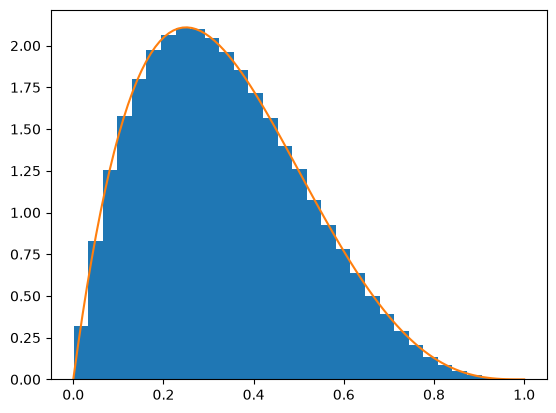

In [6]:
plt.hist(amostra, density=True, bins=30)
plt.plot(sub,f(sub))
plt.show()

3. Para cada observação gerada, registre o número de tentativas necessárias até ocorrer a primeira aceitação.

In [7]:
amostra = []
n = 1_000_000
contagens = []
for _ in range(n):
    u = np.random.uniform()
    y = np.random.uniform()
    contador = 1
    while u > f(y)/c:
        contador += 1
        u = np.random.uniform()
        y = np.random.uniform()
    contagens.append(contador)

    

In [8]:
np.mean(contagens)

np.float64(2.208796)

(array([3.63541304e-01, 4.99086957e-02, 1.48856522e-02, 5.37130435e-03,
        7.52173913e-04, 2.23913043e-04, 8.30434783e-05, 1.34782609e-05,
        2.60869565e-06, 4.34782609e-07]),
 array([ 1. ,  3.3,  5.6,  7.9, 10.2, 12.5, 14.8, 17.1, 19.4, 21.7, 24. ]),
 <BarContainer object of 10 artists>)

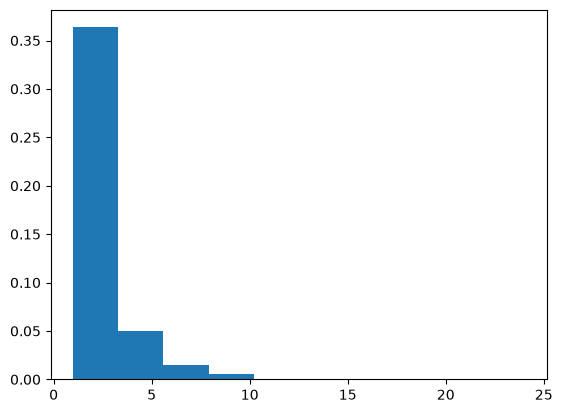

In [9]:
plt.hist(contagens, density = True)

   a. Determine teoricamente a probabilidade de aceitação do método AR.

In [10]:
# A probabilidade de aceitação segundo o método é 1/c, que nesse caso será
print(1/np.mean(contagens)) # amostral
print(1/c) # teorica

0.4527353363551908
0.45264595397456187


   b. Determine o número esperado de tentativas até a primeira aceitação.

In [11]:
print(f'O número esperado de tentativas até a primeira aceitação: {np.mean(contagens)}')

O número esperado de tentativas até a primeira aceitação: 2.208796


   c. Compare a média empírica do número de tentativas com o valor esperado teoricamente.

In [12]:
print(f'A média empírica é {np.mean(contagens)} e o valor esperado teoricamente é {c}')

A média empírica é 2.208796 e o valor esperado teoricamente é 2.209232163060931


   d. Determine a distribuição teórica do número de tentativas até a primeira aceitação e compare-a com a distribuição empírica obtida na simulação.

In [13]:
def densidade_exp(x, lamb=1):
    return lamb*np.exp(-x*lamb)

Aqui eu só  criei a função da distribuição exponencial

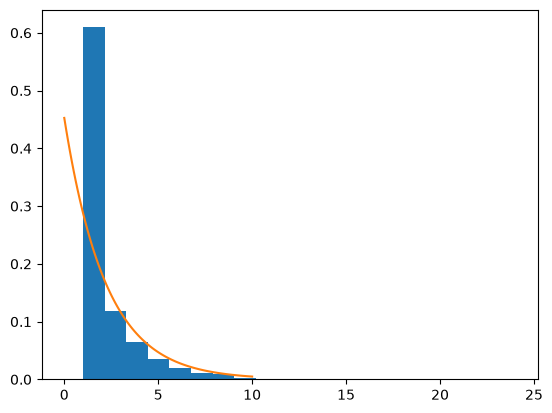

In [14]:
x = np.linspace(0,10, 100)
fx = densidade_exp(x, lamb=1/c)
plt.hist(contagens, density=True, bins=20)
plt.plot(x,fx)